# 02 · Delay Analysis

**The question:** when, where, and why do U.S. flights run late, and how much of it could airlines actually control?

I work through four hypotheses, each with one chart:

1. **Who:** reliability varies a lot by airline, not just by airport or weather.
2. **Why:** most delay minutes come from causes airlines control (their own operations and late inbound aircraft), not weather.
3. **When:** delays snowball through the day as late planes push back every later flight.
4. **Where and when in the year:** a few hubs drive the worst delays, and they cluster in summer and winter.

Every number here uses the 15-minute delay rule and the October airport fix from notebook 01.

In [1]:
import sys
sys.path.append("..")

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.load_data import load_flights, DELAY_CAUSES

sns.set_theme(style="whitegrid")
FIGURES = Path("../figures")
FIGURES.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=200, bbox_inches="tight")

df = load_flights("../data/flights.csv")
overall_rate = df["IS_DELAYED"].mean()

October airport fix: mapped 305 airport IDs, 99.97% of October flights recovered (124 left unmatched)
Loaded 5,819,079 flights | 18.6% delayed 15+ min (completed flights only)


## 1 · Who: delay rate by airline

All 14 airlines are included, regional carriers too (ExpressJet, SkyWest, Envoy). They fly under the major airlines' brands, so leaving them out hides a real part of the picture.

In [2]:
by_airline = (
    df.groupby("AIRLINE_NAME")
      .agg(flights=("IS_DELAYED", "size"),
           delay_rate=("IS_DELAYED", "mean"),
           cancel_rate=("CANCELLED", "mean"))
      .sort_values("delay_rate", ascending=False)
)
by_airline.style.format({"flights": "{:,}", "delay_rate": "{:.1%}", "cancel_rate": "{:.1%}"})

,flights,delay_rate,cancel_rate
AIRLINE_NAME,,,
Spirit,"117,379",29.7%,1.7%
Frontier,"90,836",26.2%,0.6%
JetBlue,"267,048",22.6%,1.6%
Envoy,"294,632",21.7%,5.1%
United,"515,723",20.6%,1.3%
ExpressJet,"571,977",19.7%,2.7%
Virgin America,"61,903",19.2%,0.9%
Southwest,"1,261,855",19.0%,1.3%
US Airways,"198,715",18.8%,2.0%


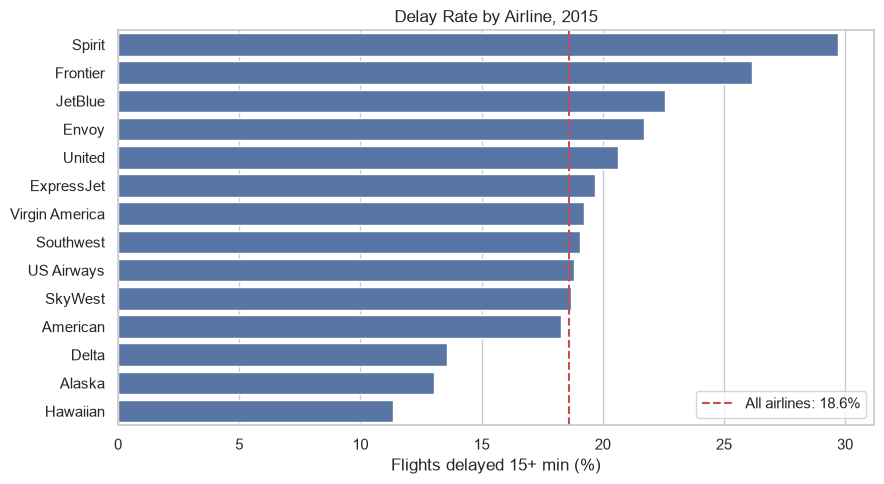

In [3]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(x=by_airline["delay_rate"] * 100, y=by_airline.index, color="#4C72B0", ax=ax)
ax.axvline(overall_rate * 100, color="#C44E52", linestyle="--", label=f"All airlines: {overall_rate:.1%}")
ax.set_xlabel("Flights delayed 15+ min (%)")
ax.set_ylabel("")
ax.set_title("Delay Rate by Airline, 2015")
ax.legend()
plt.tight_layout()
save(fig, "01_delay_rate_by_airline")
plt.show()

## 2 · Why: what causes the delay minutes

For every flight 15+ minutes late, the airline reports how many minutes came from each cause. Adding up all those minutes shows where delay time really comes from.

- **Controllable by the airline:** its own operations (crew, maintenance, boarding, fueling) and late inbound aircraft (the plane showed up late from its last flight)
- **Outside the airline's control:** the air traffic system (congestion, air traffic control), weather, and security

In [4]:
cause_cols = list(DELAY_CAUSES)
cause_minutes = df[cause_cols].sum().rename(index=DELAY_CAUSES).sort_values(ascending=False)
cause_share = cause_minutes / cause_minutes.sum()

controllable = cause_share[["Late inbound aircraft", "Airline (crew, maintenance, ops)"]].sum()
print(f"Total delay minutes: {cause_minutes.sum() / 1e6:.1f}M")
print(f"Share controllable by airlines: {controllable:.1%}")
cause_share.map("{:.1%}".format)

Total delay minutes: 62.7M
Share controllable by airlines: 72.0%


Late inbound aircraft               39.8%
Airline (crew, maintenance, ops)    32.2%
Air traffic system                  22.9%
Weather                              4.9%
Security                             0.1%
dtype: str

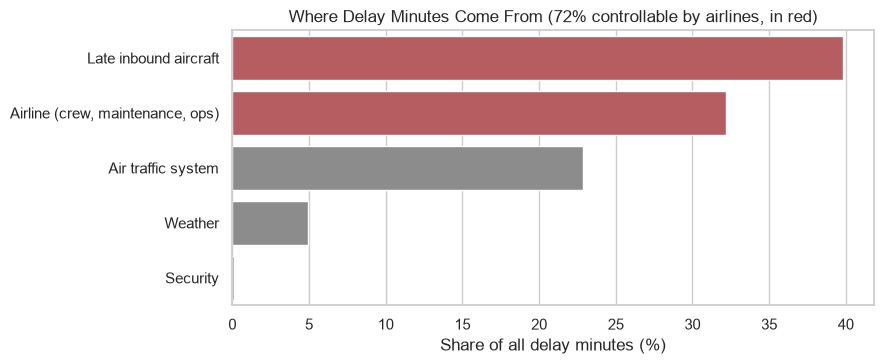

In [5]:
fig, ax = plt.subplots(figsize=(9, 3.8))
colors = ["#C44E52" if c in ("Late inbound aircraft", "Airline (crew, maintenance, ops)") else "#8C8C8C"
          for c in cause_share.index]
sns.barplot(x=cause_share.values * 100, y=cause_share.index, hue=cause_share.index, palette=colors, legend=False, ax=ax)
ax.set_xlabel("Share of all delay minutes (%)")
ax.set_ylabel("")
ax.set_title(f"Where Delay Minutes Come From ({controllable:.0%} controllable by airlines, in red)")
plt.tight_layout()
save(fig, "02_delay_causes")
plt.show()

In [6]:
# Does the cause mix differ by airline? Share of each airline's delay minutes that it controls
airline_causes = df.groupby("AIRLINE_NAME")[cause_cols].sum()
airline_controllable = (
    airline_causes[["AIRLINE_DELAY", "LATE_AIRCRAFT_DELAY"]].sum(axis=1) / airline_causes.sum(axis=1)
).sort_values(ascending=False)
airline_controllable.map("{:.1%}".format)

AIRLINE_NAME
Hawaiian          94.7%
Southwest         82.0%
SkyWest           75.5%
United            72.9%
ExpressJet        72.9%
American          71.3%
JetBlue           69.0%
Alaska            67.8%
Delta             67.0%
Envoy             64.8%
US Airways        63.1%
Frontier          61.9%
Virgin America    58.2%
Spirit            54.2%
dtype: str

## 3 · When: do delays snowball through the day?

If late inbound aircraft is a big cause, delays should build as the day goes on: one late plane makes every later flight on that aircraft late too. If that's true, both the delay rate and the late-aircraft minutes should climb from morning to evening.

In [7]:
by_hour = (
    df.groupby("DEP_HOUR")
      .agg(flights=("IS_DELAYED", "size"),
           delay_rate=("IS_DELAYED", "mean"),
           late_aircraft_min=("LATE_AIRCRAFT_DELAY", "mean"))
)
by_hour = by_hour.loc[5:23]

morning = by_hour.loc[5:8, "delay_rate"].mean()
evening = by_hour.loc[17:20, "delay_rate"].mean()
print(f"Delay rate, 5-8am departures: {morning:.1%}")
print(f"Delay rate, 5-8pm departures: {evening:.1%}  ({evening / morning:.1f}x the morning rate)")
by_hour.style.format({"flights": "{:,}", "delay_rate": "{:.1%}", "late_aircraft_min": "{:.1f}"})

Delay rate, 5-8am departures: 10.1%
Delay rate, 5-8pm departures: 25.7%  (2.5x the morning rate)


,flights,delay_rate,late_aircraft_min
DEP_HOUR,,,
5,"118,051",7.3%,2.7
6,"406,940",9.0%,3.0
7,"393,947",11.2%,6.0
8,"381,014",12.9%,10.1
9,"351,403",14.2%,16.0
10,"371,644",15.4%,21.1
11,"358,084",16.4%,22.4
12,"355,611",17.6%,24.6
13,"363,509",19.0%,24.4


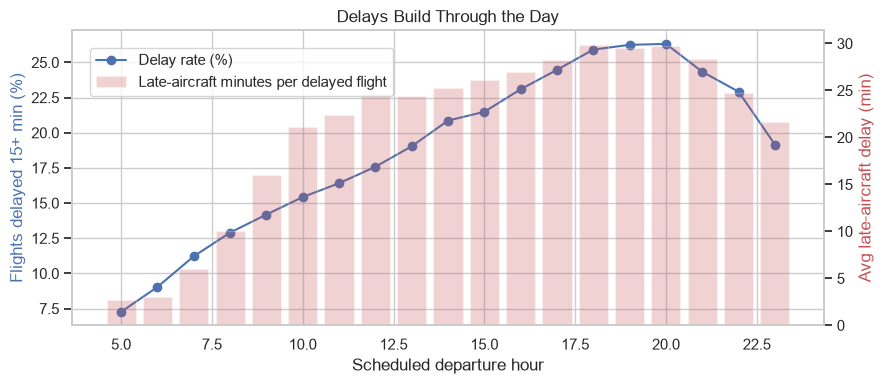

In [8]:
fig, ax1 = plt.subplots(figsize=(9, 4))
ax1.plot(by_hour.index, by_hour["delay_rate"] * 100, marker="o", color="#4C72B0", label="Delay rate (%)")
ax1.set_xlabel("Scheduled departure hour")
ax1.set_ylabel("Flights delayed 15+ min (%)", color="#4C72B0")

ax2 = ax1.twinx()
ax2.bar(by_hour.index, by_hour["late_aircraft_min"], alpha=0.25, color="#C44E52", label="Late-aircraft minutes per delayed flight")
ax2.set_ylabel("Avg late-aircraft delay (min)", color="#C44E52")
ax2.grid(False)

ax1.set_title("Delays Build Through the Day")
fig.legend(loc="upper left", bbox_to_anchor=(0.1, 0.88))
plt.tight_layout()
save(fig, "03_delays_by_hour")
plt.show()

## 4 · Where and when in the year: busiest airports by month

This is the heatmap from my original project, now with October included and the 15-minute rule. Darker red means more delays.

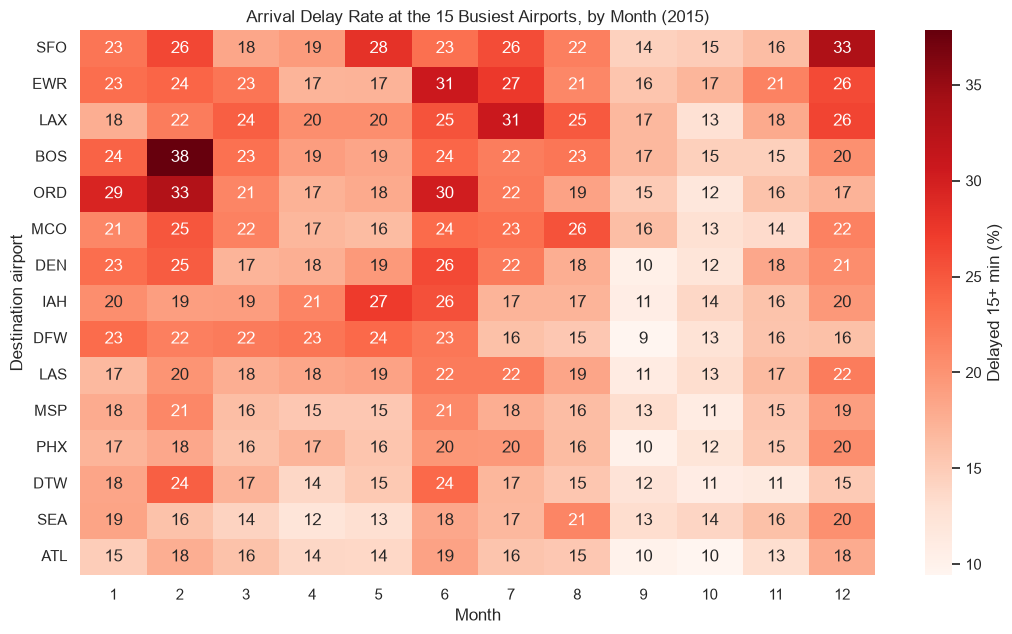

In [9]:
top_airports = df["DESTINATION_AIRPORT"].value_counts().head(15).index
heat = (
    df[df["DESTINATION_AIRPORT"].isin(top_airports)]
      .groupby(["DESTINATION_AIRPORT", "MONTH"])["IS_DELAYED"].mean()
      .unstack("MONTH")
)
heat = heat.loc[heat.mean(axis=1).sort_values(ascending=False).index]  # worst airports on top

fig, ax = plt.subplots(figsize=(11, 6.5))
sns.heatmap(heat * 100, cmap="Reds", annot=True, fmt=".0f", cbar_kws={"label": "Delayed 15+ min (%)"}, ax=ax)
ax.set_title("Arrival Delay Rate at the 15 Busiest Airports, by Month (2015)")
ax.set_xlabel("Month")
ax.set_ylabel("Destination airport")
plt.tight_layout()
save(fig, "04_airport_month_heatmap")
plt.show()

In [10]:
worst = heat.mean(axis=1).sort_values(ascending=False)
monthly = df.groupby("MONTH")["IS_DELAYED"].mean()
print("Worst 3 airports:", ", ".join(f"{a} {r:.1%}" for a, r in worst.head(3).items()))
print("Best 3 airports: ", ", ".join(f"{a} {r:.1%}" for a, r in worst.tail(3).items()))
print("Worst month:", monthly.idxmax(), f"{monthly.max():.1%}", "| Best month:", monthly.idxmin(), f"{monthly.min():.1%}")

Worst 3 airports: SFO 22.0%, EWR 22.0%, LAX 21.7%
Best 3 airports:  DTW 16.3%, SEA 16.1%, ATL 14.7%
Worst month: 6 23.5% | Best month: 10 12.4%


## What this means

**1 · Who: confirmed.** Airline matters a lot. Hawaiian (11.3%), Alaska (13.0%), and Delta (13.6%) were the most reliable, and Spirit (29.7%) and Frontier (26.2%) the least. That's a 2.6x gap. Size isn't the excuse: Delta flew 876K flights and still had the third-best rate.

**2 · Why: confirmed.** 72% of the 62.7M delay minutes came from causes airlines control: late inbound aircraft (39.8%) and the airline's own operations (32.2%). Weather was only 4.9%. One caveat: the DOT files non-extreme weather under "air traffic system" (22.9%), so weather's real share is somewhat higher than 4.9%. Even so, most delay time starts with the airline. Spirit is the exception worth a follow-up: worst delay rate, but the lowest controllable share (54%), so more of its delays come from the air traffic system.

**3 · When: confirmed, and this is the strongest finding.** Flights leaving 5-8am were delayed 10.1% of the time, and flights leaving 5-8pm 25.7%, which is 2.5x worse. Late-aircraft delay explains why. A delayed 6am flight carries about 3 minutes of late-aircraft delay, while a delayed 6pm flight carries about 30. Delays from earlier flights stack up on every later flight that aircraft flies.

**4 · Where and when in the year: partly true.** Delays peak in summer (June: 23.5% delayed, the worst month) and in winter storms (February hit 38% at Boston and 33% at Chicago O'Hare). Fall is the calmest stretch, with October the best month (12.4%). That's the month my original version was missing entirely. Among the 15 busiest airports, the spread is smaller than I expected: San Francisco and Newark were worst (22.0%) and Atlanta, the busiest airport in the country, was best (14.7%). Airport matters less than airline and time of day.

### So what
If I were advising an airline, the data points to fixing operations before blaming weather or airports:
- **Protect the morning.** Most delay minutes come from late planes passing delays down the line, so an on-time first wave keeps the whole day cleaner.
- **Add turnaround buffer on afternoon and evening rotations**, where late-aircraft delay is about 10x the morning level.
- **Benchmark against Delta and Alaska**, who run large networks at roughly half Spirit's delay rate.

*Limitations: this is one year (2015) of U.S. domestic flights. Several of these airlines have since merged or rebranded, so the next step is re-running the same pipeline on recent BTS data.*